# Synthetic overlap study

Compare rPIE, LSQML, GM-rPIE, and GM-MAGPIE at **75%, 87.5%, and 93.75% overlap**, using **3,000, 800, and 200 epochs**, respectively. The overlap is $1-s/128$, where $s$ is the nominal scan step in pixels. All runs use $\eta=0.1$ and minibatches of 27 scan positions.

This notebook includes the saved results, so the tables and figures are visible on GitHub without running a reconstruction.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (path / "pyproject.toml").is_file()
            and (path / "results" / "endpoints.csv").is_file())
sys.path.insert(0, str(ROOT / "src"))
pd.options.display.float_format = lambda value: f"{value:.4g}"

from blind_magpie.results import selected_cases, plot_sweep_heatmaps, plot_convergence, show_figure
STUDY = "overlap"

## Ground truth and initialization

The object is $1024\times1024$ and the probe is $128\times128$. Object magnitude comes from Baboon and phase from Cameraman. The true and initial probes use settings of $-700$ and $-400\,\mu\mathrm m$, and the initial object is one.


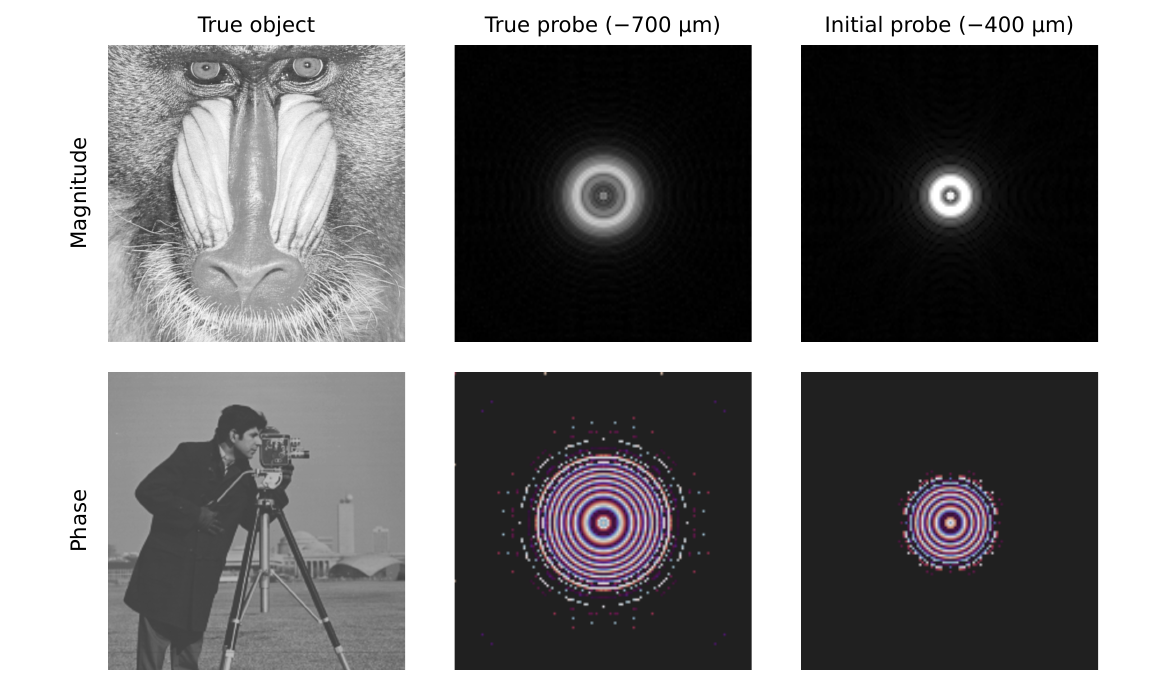

In [2]:
display(show_figure("numerical_synthetic_setup"))

## Selected parameters

Each PIE method searches nine pairs with both alphas in `[0.004, 0.02, 0.1]`. LSQML searches sixteen damping–$\sigma$ pairs, with damping `[0.04, 0.1, 0.2, 1]` and $\sigma$ `[0.3, 0.4, 0.5, 0.6]`. Selection uses the lowest final **object** NMSE among completed runs.


In [3]:
selected = selected_cases(STUDY)
display(selected[["method", "overlap", "eta", "batch_size", "epochs", "parameters", "object_nmse", "probe_nmse"]])

,method,overlap,eta,batch_size,epochs,parameters,object_nmse,probe_nmse
0,rpie,0.75,0.1,27,3000,"αO=0.02, αP=0.1",0.007995,0.3978
1,lsqml,0.75,0.1,27,3000,"damping=0.04, σ=0.4",0.03178,0.9319
2,gm_rpie,0.75,0.1,27,3000,"αO=0.02, αP=0.1",0.002286,7.279e-05
3,gm_magpie,0.75,0.1,27,3000,"αO=0.1, αP=0.02",0.002079,0.0001374
4,rpie,0.875,0.1,27,800,"αO=0.004, αP=0.1",0.003855,0.0009692
5,lsqml,0.875,0.1,27,800,"damping=0.2, σ=0.3",0.01255,0.0001809
6,gm_rpie,0.875,0.1,27,800,"αO=0.02, αP=0.1",0.0003535,1.172e-05
7,gm_magpie,0.875,0.1,27,800,"αO=0.1, αP=0.004",8.381e-05,1.114e-05
8,rpie,0.9375,0.1,27,200,"αO=0.02, αP=0.1",0.0002344,4.606e-05
9,lsqml,0.9375,0.1,27,200,"damping=0.2, σ=0.4",0.01221,5.813e-05


## Parameter sweeps

Each panel shows final object NMSE. Boxes mark the selected pairs; cells labelled `failed` retain unsuccessful candidates.


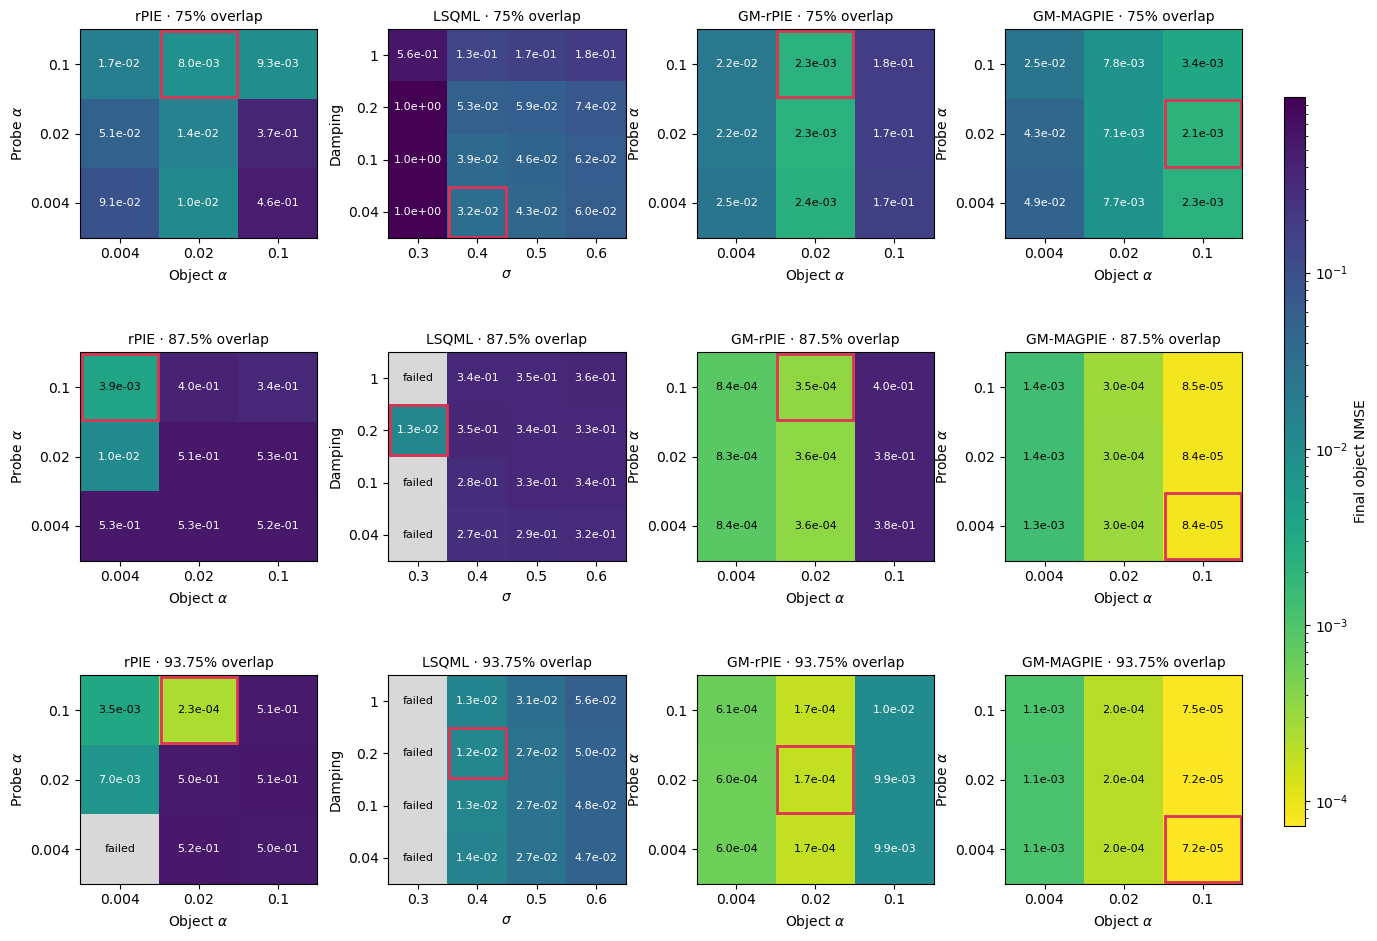

In [4]:
display(plot_sweep_heatmaps(STUDY))
plt.close("all")

## Object and probe convergence

The curves report normalized squared complex errors,
$\mathrm{NMSE}_X=\|X_{\mathrm{al}}-X^\star\|_2^2/\|X^\star\|_2^2$.
The object is aligned by a complex scale and affine phase ramp on the common scanned region. The probe uses the corresponding ambiguity correction and its remaining global phase is removed.


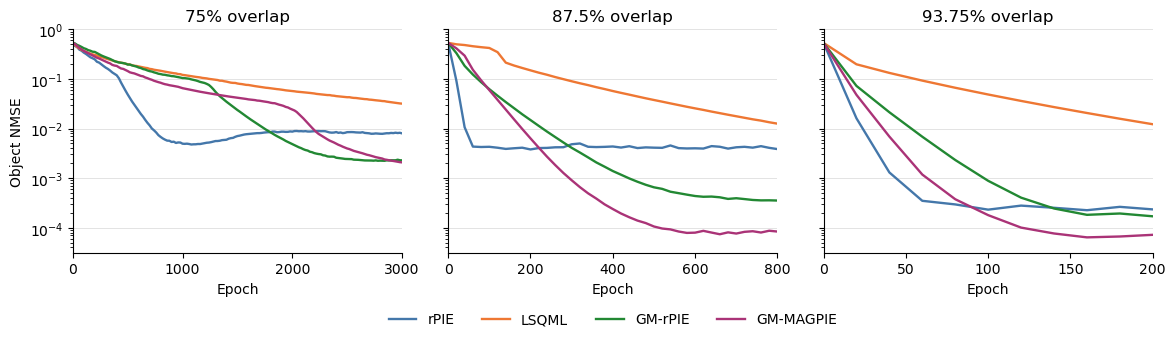

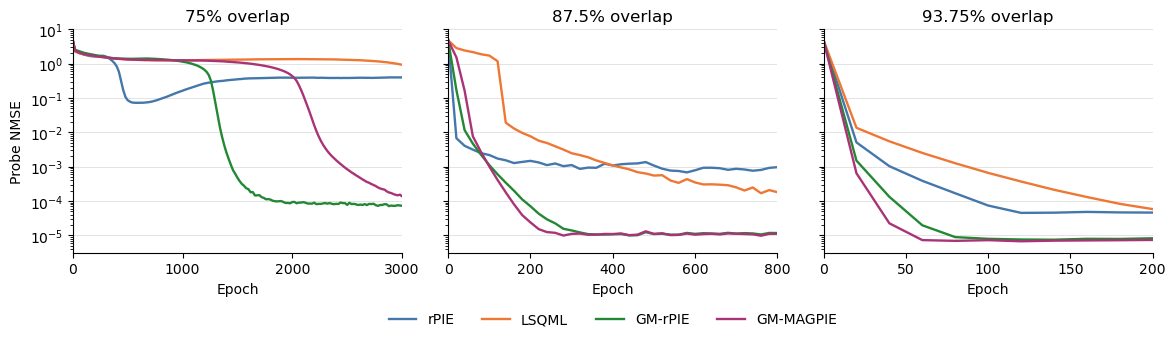

In [5]:
display(plot_convergence(STUDY, metric="object"))
display(plot_convergence(STUDY, metric="probe"))
plt.close("all")

## Reconstructions at 87.5% overlap

The object and probe panels use the same selected runs as the convergence curves. Rows show magnitude, phase, and absolute complex error; error images use a logarithmic scale.


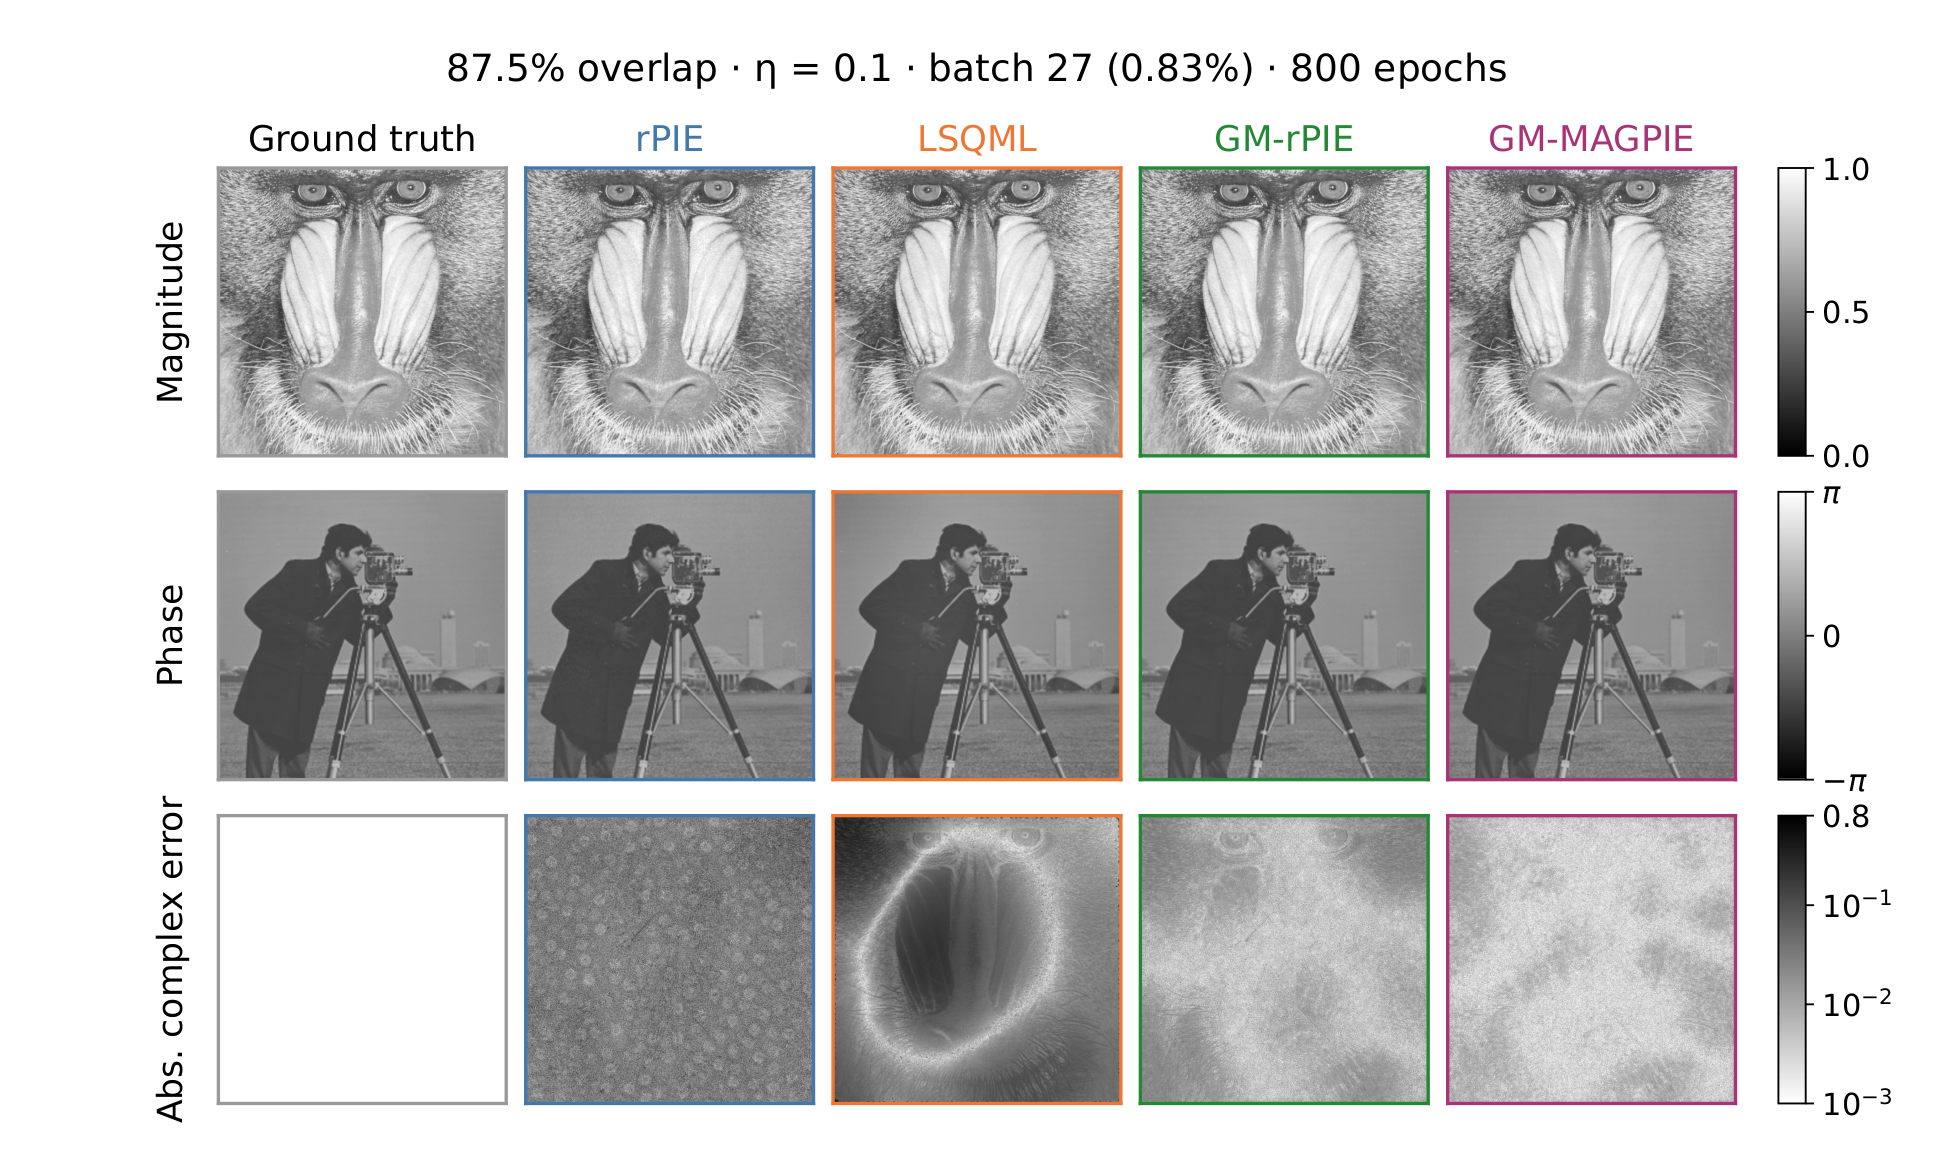

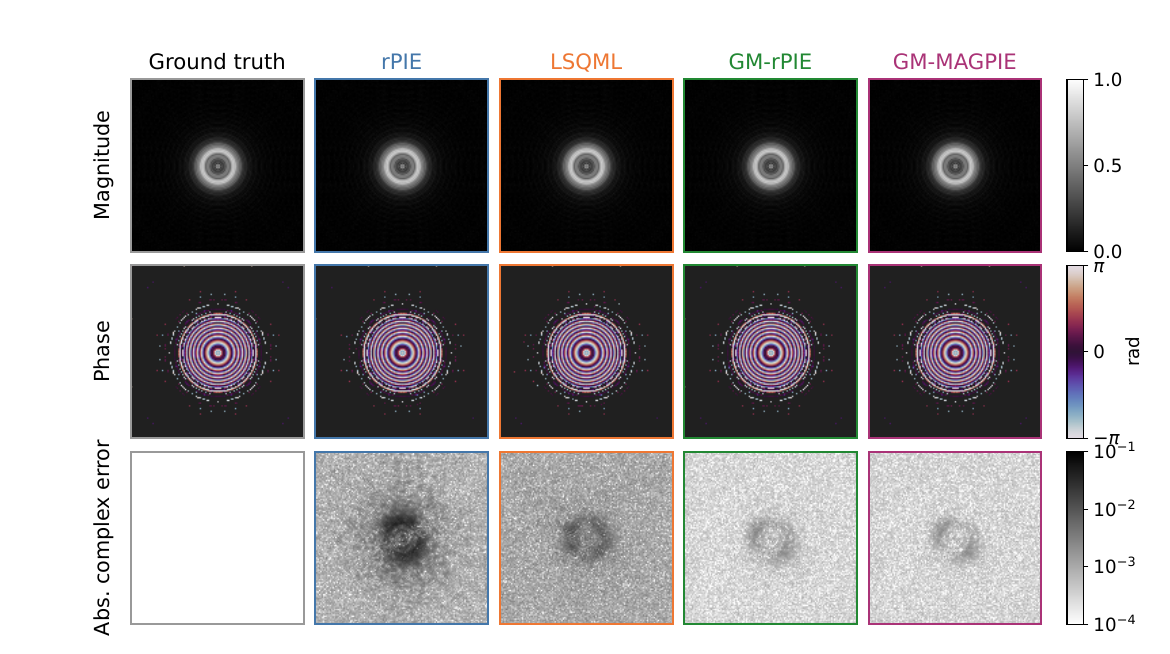

In [6]:
display(show_figure("numerical_0875_baseline_objects"))
display(show_figure("numerical_synthetic_probe_reconstructions"))

## Reproduce the synthetic reconstructions

The cells above use the recorded results and run on CPU. To compute new reconstructions, install the reconstruction dependencies and use a CUDA GPU. Set the flag below to `True` to rerun the selected parameter pairs; new outputs go into `runs/`.


In [7]:
RUN_RECONSTRUCTIONS = False
if RUN_RECONSTRUCTIONS:
    from blind_magpie import run_experiments
    display(run_experiments(STUDY, mode="selected", output=ROOT / "runs"))
